In [168]:
data = {
    'Height': [170, 165, 180, 175, 160, 172, 168, 177, 162, 158],
    'Weight': [65, 59, 75, 68, 55, 70, 62, 74, 58, 54],
    'Age': [30, 25, 35, 28, 22, 32, 27, 33, 24, 21],
    'Gender': [1, 0, 1, 1, 0, 1, 0, 1, 0, 0]  # 1 = Male, 0 = Female
}
import pandas as pd
df=pd.DataFrame(data)
print(df)

   Height  Weight  Age  Gender
0     170      65   30       1
1     165      59   25       0
2     180      75   35       1
3     175      68   28       1
4     160      55   22       0
5     172      70   32       1
6     168      62   27       0
7     177      74   33       1
8     162      58   24       0
9     158      54   21       0


          Height    Weight       Age    Gender
Height  1.000000  0.980484  0.947482  0.864314
Weight  0.980484  1.000000  0.976122  0.887520
Age     0.947482  0.976122  1.000000  0.863263
Gender  0.864314  0.887520  0.863263  1.000000


<Axes: >

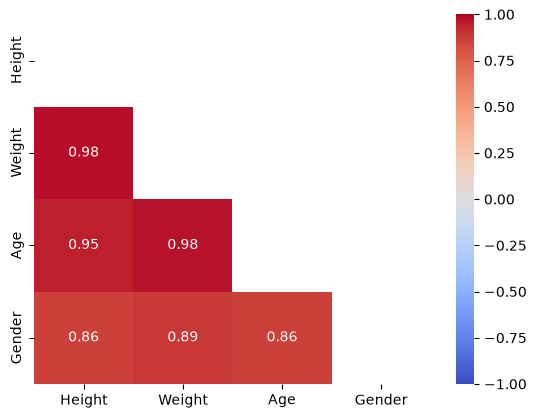

In [169]:
corr_matrix=df.corr()
print(corr_matrix)
import numpy as np
mask=np.triu(np.ones_like(corr_matrix,dtype=bool))
import seaborn as sns
sns.heatmap(corr_matrix,
            annot=True,
            mask=mask,
            fmt=".2f",
            cmap="coolwarm",
            vmin=-1,
            vmax=1,
            )

[[ 0.41026956  0.23565377]
 [-1.08380468 -0.033722  ]
 [ 2.6257266   0.00824886]
 [ 0.80628567 -0.56592522]
 [-2.17106163 -0.0066209 ]
 [ 1.21967079  0.32176838]
 [-0.35818854 -0.02366354]
 [ 2.06301165 -0.01845245]
 [-1.52456158  0.09613655]
 [-2.53270244  0.03053865]]
PCA(n_components=2)
[ True False  True  True  True  True  True False False  True]
Variance ratio per component: [0.97413543 0.02290207]


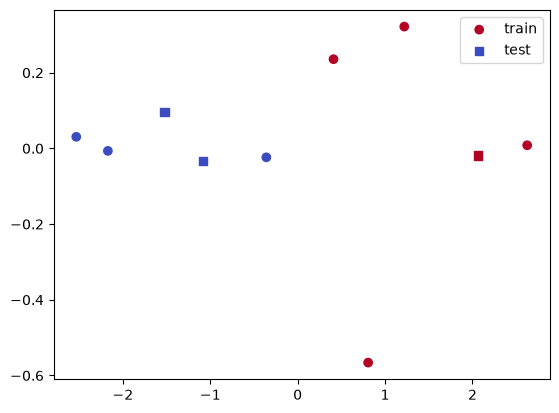

In [170]:
# standardize: mean=0, standard deviation=1
X=df.drop('Gender',axis=1)
y=df['Gender']
# y_numeric,classes=pd.factorize(y)
# # convert label to integer(0,1,2), the first item label as 0, second label as 1, third label as 2, and so on 
# # similar to map method 
# # Factorizing y_train alone can number the labels differently from the full data, depending on which label appears first in the training split. Factorizing before the split avoids that.
# print(y_numeric,classes)

from sklearn.model_selection import KFold, train_test_split,cross_val_predict,cross_val_score
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)
# stratify=y ensures that the training and test datasets maintain the exact same proportion of class labels as the original dataset
from sklearn.preprocessing import StandardScaler
scaler_fit=StandardScaler().fit(X_train)
scaler_train=scaler_fit.transform(X_train)
scaler_all=scaler_fit.transform(X)
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
pca_fit=pca.fit(scaler_train)
pca_train=pca_fit.transform(scaler_train)
pca_all=pca_fit.transform(scaler_all)
print(pca_all)
print("="*50)
print(pca_fit)
is_train=X.index.isin(X_train.index)
print(is_train)
import matplotlib.pyplot as plt
plt.scatter(pca_all[is_train,0],pca_all[is_train,1],c=y[is_train],cmap='coolwarm',marker='o',label='train')
plt.scatter(pca_all[~is_train,0],pca_all[~is_train,1],c=y[~is_train],cmap='coolwarm',marker='s',label='test')
plt.legend()
ratios = pca.explained_variance_ratio_
print("Variance ratio per component:", ratios)

              precision    recall  f1-score   support

           0       0.50      0.50      0.50         2
           1       0.00      0.00      0.00         1

    accuracy                           0.33         3
   macro avg       0.25      0.25      0.25         3
weighted avg       0.33      0.33      0.33         3



<Axes: >

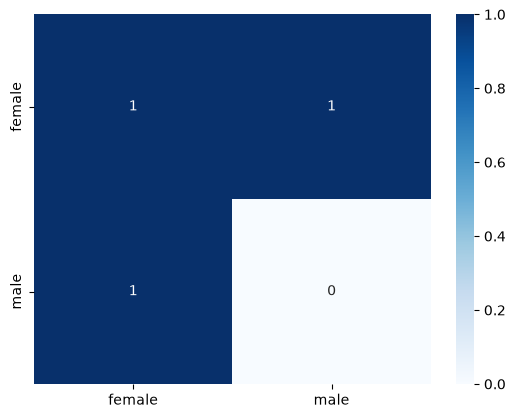

In [171]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(pca_train,y_train)
y_pred=model.predict(pca_all[~is_train])

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
print(classification_report(y_test,y_pred))
cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['female','male'],yticklabels=['female','male'])

In [172]:
print(type(y))
print(y.shape)

<class 'pandas.Series'>
(10,)


Text(0.5, 1.0, 'After PCA')

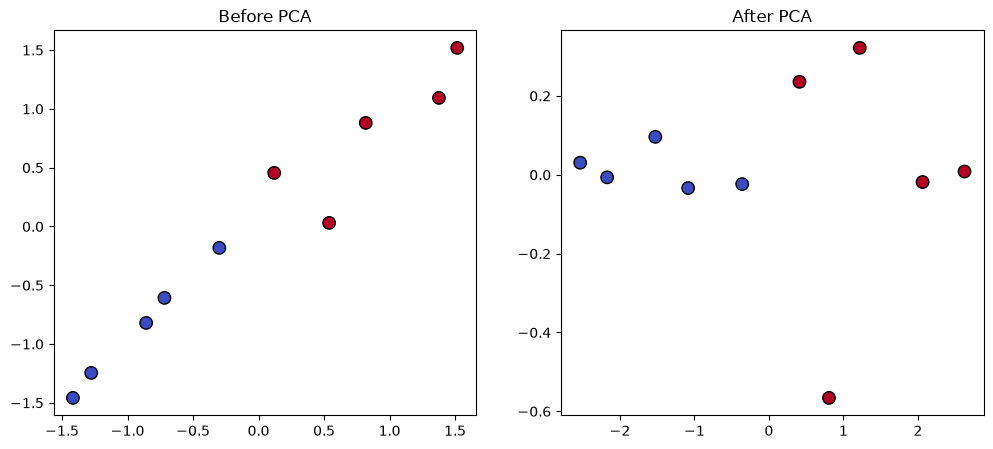

In [173]:

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.scatter(scaler_all[:, 1], scaler_all[:, 2], c=y, cmap='coolwarm', edgecolor='k', s=80)
plt.title("Before PCA")
plt.subplot(1,2,2)
plt.scatter(pca_all[:, 0], pca_all[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=80)
plt.title("After PCA")
# It draws where each person lands after projecting onto pca vector
# example for the person with Height 180, Weight 75, Age 35. Their z-scores are about (1.60, 1.53, 1.62), so PC1 ≈ 2.74 and PC2 ≈ 0.02. That is the red point at the far right of plot.

[[ 0.57519703  0.58318458  0.57362367]
 [-0.67394876 -0.05958124  0.73637161]]


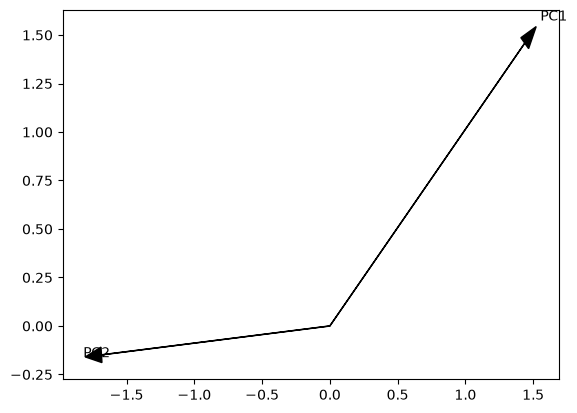

In [174]:
print(pca.components_)
for v, name in zip(pca.components_, ['PC1', 'PC2']):
# zip: pairs each component vector (v) with a text label (name).the loop runs twice: first for PC1, then for PC2.
    plt.arrow(0, 0, v[0]*2.5, v[1]*2.5, head_width=0.08, color='k')
    plt.text(v[0]*2.7, v[1]*2.7, name)
# v[0]*2.7, v[1]*2.7: This places the text label ('PC1' or 'PC2') slightly past the tip of the arrow (using a multiplier of 2.7 instead of 2.5) so the text doesn't overlap with the arrowhead.

[1.  0.5 1.  1.  1. ]
              precision    recall  f1-score   support

           0       0.83      1.00      0.91         5
           1       1.00      0.80      0.89         5

    accuracy                           0.90        10
   macro avg       0.92      0.90      0.90        10
weighted avg       0.92      0.90      0.90        10



(np.float64(-2.795184087687531),
 np.float64(3.001106147694542),
 np.float64(-0.6322351820684614),
 np.float64(0.38305843793003347))

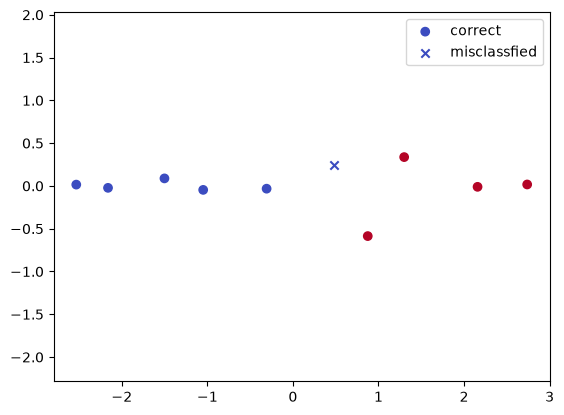

In [175]:
from sklearn.pipeline import make_pipeline
pipe=make_pipeline(StandardScaler(),PCA(n_components=2),LogisticRegression())
kf=KFold(n_splits=5,shuffle=True,random_state=42)
print(cross_val_score(pipe,X,y,cv=kf))
y_pred=cross_val_predict(pipe,X,y,cv=kf)
print(classification_report(y,y_pred))
correct=(y_pred==y.values)
Xp=make_pipeline(StandardScaler(),PCA(n_components=2)).fit_transform(X)
plt.scatter(Xp[correct,0],Xp[correct,1],c=y[correct],cmap='coolwarm',marker='o',label='correct')
plt.scatter(Xp[~correct,0],Xp[~correct,1],c=y[~correct],cmap='coolwarm',marker='x',label='misclassfied')
plt.legend()
plt.axis('equal')

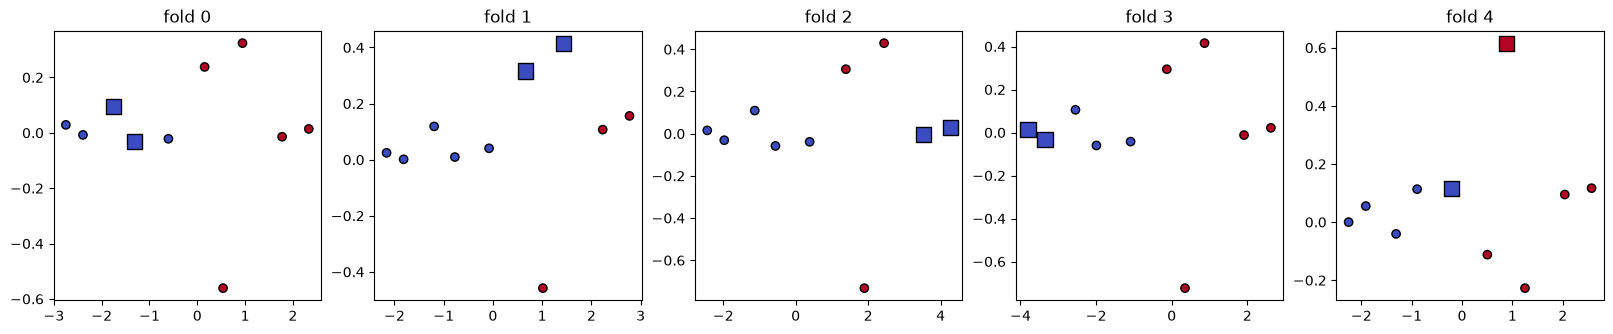

In [176]:
fig, axs = plt.subplots(1, 5, figsize=(20, 3.5))
for k, (tr, va) in enumerate(kf.split(X)):
    m = make_pipeline(StandardScaler(), PCA(n_components=2)).fit(X.iloc[tr])  # fit on train fold only
    Ztr, Zva = m.transform(X.iloc[tr]), m.transform(X.iloc[va])
    axs[k].scatter(Ztr[:, 0], Ztr[:, 1], c=y.iloc[tr], cmap='coolwarm', edgecolor='k', marker='o')
    axs[k].scatter(Zva[:, 0], Zva[:, 1], c=y.iloc[va], cmap='coolwarm', edgecolor='k', marker='s', s=120)
    axs[k].set_title(f'fold {k}')
